In [ ]:
# This cell imports necessary dataset and libraries. Do not change it.
# Data source: Quinlan, R. (1993). Auto MPG [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C5859H.
!pip install ucimlrepo
from ucimlrepo import fetch_ucirepo
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error
from sklearn.preprocessing import MinMaxScaler
from matplotlib import pyplot as plt
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense

# fetch dataset
auto_mpg = fetch_ucirepo(id=9)

# data (as pandas dataframes)
X = auto_mpg.data.features
y = auto_mpg.data.targets

In [ ]:
# Data cleaning
# This dataset is already split into X and y. Only X contains NaN.
# Drop NaN from both X and corresponding y.
df = pd.concat([X, y], axis=1) # This makes the combined dataframe along the columns (axis=1).
df_clean = df.dropna()  # Drop the rows containing the missing values.
X_clean = df_clean.drop(columns=['mpg'])  # Drop the target column.
y_clean = df_clean['mpg']  # Keep only the target column.

In [ ]:
# Write the code to split the data into training and test sets.
x_train, x_test, y_train, y_test = train_test_split(X_clean, y_clean, test_size=0.3, random_state=42)

In [ ]:
# Write the code to normalize the input by first creating a scaler with the training data and then applying it to transform both the training and test datasets.
# 1. Setup the scaling tool.
scaler = MinMaxScaler()
# 2. Fit the scaler on the training data.
x_train_scaled = scaler.fit_transform(x_train)
# 3. Transform the testing data using the fitted scaler.
x_test_scaled = scaler.transform(x_test)

In [ ]:
# This uses the fixed initial parameters in the DL model.
tf.keras.utils.set_random_seed(42)

In [ ]:
# Write the code to create your deep learning model.
model = Sequential()
model.add(Input(shape=(x_train.shape[1],)))
model.add(Dense(100,activation='relu'))
model.add(Dense(70,activation='relu'))
model.add(Dense(8,activation='relu'))
model.add(Dense(1,activation='relu'))

In [ ]:
# Write the code to compile the model.
model.compile(loss='mae', optimizer='adam', metrics=['mae'])

In [ ]:
# Write the code to train the model with the training data.
model.fit(x_train_scaled, y_train, epochs=1000, batch_size=64)

Epoch 1/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.0061 - mae: 2.0061 
Epoch 2/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.9963 - mae: 1.9963 
Epoch 3/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.9904 - mae: 1.9904 
Epoch 4/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.9798 - mae: 1.9798 
Epoch 5/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 2.0321 - mae: 2.0321 
Epoch 6/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.9797 - mae: 1.9797 
Epoch 7/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 2.0126 - mae: 2.0126 
Epoch 8/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.9664 - mae: 1.9664 
Epoch 9/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 1.9568 - mae: 1.9568 
Epoch 10/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.9585 - mae: 1.9585 
Epoch 11/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.9398 - mae: 1.9398 
Epoch 12/1000
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 1.9487 - mae: 1.9487 
Epoch 13/1000
5/5 ━━━━━━━━━━━━━━━━━━━

In [ ]:
# Write the code to make predictions with the test data.
y_predict = model.predict(x_test_scaled)

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step


In [ ]:
# Write the code to calculate MAE, using the test data and the predctions.
mean_absolute_error(y_test, y_predict)

1.8084742546081545

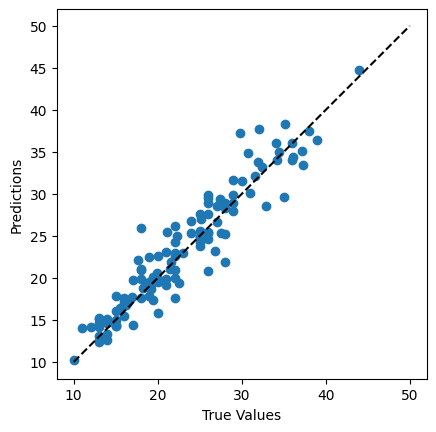

In [ ]:
# Visualize the predictions and actual values using a scatter plot with a y=x line.
plt.scatter(y_test,y_predict)
plt.xlabel('True Values')
plt.gca().set_aspect('equal')
plt.ylabel('Predictions')
plt.plot([10, 50], [10, 50], 'k--', label='y=x') # (Optional) this is a reference line. k means black. -- means dashed.
plt.show()